# EN3160 Assignment 3 — Neural Networks

**Name:** D. P. Heshan Ranasinghe  
**Index:** 230521E  
**GitHub profile:** [DPHeshanRanasinghe](https://github.com/DPHeshanRanasinghe)

This assignment covers three experiments: a manually implemented neural network for CIFAR-10 classification, a comparison of LeNet-5 and a modern CNN on MNIST, and ResNet18 transfer learning using fine-tuning and feature extraction on the hymenoptera dataset.

## Setup

The experiments use PyTorch, torchvision, NumPy, pandas and matplotlib. Computation runs on a CUDA GPU when available; otherwise, it uses the CPU. Accuracies are displayed as percentages in the result tables.

In [25]:
import os

# Configure deterministic CUDA operations before importing PyTorch.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import copy
import json
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from IPython.display import display, HTML

SEED = 230521
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = Path("data")
RESULT_DIR = Path("results")

Q1_EPOCHS = 10
Q2_EPOCHS = 10
Q3_EPOCHS = 25

NUM_WORKERS = 0


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def make_loader(dataset, batch_size, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        generator=generator,
        pin_memory=(DEVICE.type == "cuda"),
    )


seed_everything()

print(f"Device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")

Device: cuda
PyTorch version: 2.5.1


In [26]:
display(HTML("""
<style>
@page {
    size: A4 portrait;
    margin: 12mm;
}

@media print {
    body,
    .jp-RenderedHTMLCommon,
    .text_cell_render {
        font-family: Arial, sans-serif;
        font-size: 9pt;
        line-height: 1.15;
        color: #111;
    }

    .jp-Notebook {
        padding: 0 !important;
        margin: 0 !important;
        max-width: none !important;
    }

    .jp-Cell {
        margin-bottom: 4pt !important;
    }

    pre,
    code {
        font-family: Consolas, "DejaVu Sans Mono", monospace;
        font-size: 7pt;
    }

    pre {
        white-space: pre-wrap !important;
        overflow-wrap: anywhere;
    }

    .jp-InputPrompt,
    .jp-OutputPrompt,
    .prompt,
    .anchor-link {
        display: none !important;
    }

    h1, h2, h3 {
        break-after: avoid;
        page-break-after: avoid;
    }

    table {
        border-collapse: collapse;
        font-size: 8pt;
        break-inside: avoid;
    }

    th, td {
        padding: 3pt 5pt;
    }

    .jp-RenderedImage,
    .output_png {
        break-inside: avoid;
    }

    img {
        max-width: 100% !important;
        height: auto;
    }
}
</style>
"""))

In [27]:
def plot_histories(histories, heldout="test"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

    for name, history in histories.items():
        frame = pd.DataFrame(history)

        for split, style in [("train", "-"), (heldout, "--")]:
            label = f"{name}: {split}"

            axes[0].plot(
                frame["epoch"],
                frame[f"{split}_loss"],
                linestyle=style,
                label=label,
            )

            axes[1].plot(
                frame["epoch"],
                100 * frame[f"{split}_acc"],
                linestyle=style,
                label=label,
            )

    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)")

    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    fig.tight_layout()
    plt.show()


def result_table(names, results, heldout="test"):
    rows = []

    for name in names:
        metrics = results[name]

        rows.append({
            "Model / method": name,
            "Training loss": metrics["train_loss"],
            "Training accuracy (%)": 100 * metrics["train_acc"],
            f"{heldout.title()} loss": metrics[f"{heldout}_loss"],
            f"{heldout.title()} accuracy (%)":
                100 * metrics[f"{heldout}_acc"],
        })

    table = pd.DataFrame(rows)

    display(
        table.style
        .format({
            "Training loss": "{:.4f}",
            "Training accuracy (%)": "{:.2f}",
            f"{heldout.title()} loss": "{:.4f}",
            f"{heldout.title()} accuracy (%)": "{:.2f}",
        })
        .hide(axis="index")
    )


def save_run(name, history, metrics, state):
    RESULT_DIR.mkdir(parents=True, exist_ok=True)

    pd.DataFrame(history).to_csv(
        RESULT_DIR / f"{name}_history.csv",
        index=False,
    )

    metadata = {
        **metrics,
        "seed": SEED,
        "device": str(DEVICE),
        "torch_version": str(torch.__version__),
    }

    with open(
        RESULT_DIR / f"{name}_metrics.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(metadata, file, indent=2)

    torch.save(state, RESULT_DIR / f"{name}.pt")

## Q1 — Manual CIFAR-10 dense network

The network takes a flattened CIFAR-10 image with 3072 values, passes it through 100 sigmoid hidden units, and produces 10 output logits. Images are normalised to [-1, 1]. The forward pass, cross-entropy loss, gradients and parameter updates are implemented manually without automatic differentiation.

Training uses Xavier initialisation, a batch size of 50, and 10 epochs. The learning rate is multiplied by 0.9 after each epoch.

### Learning-rate selection

Initial learning rates of 0.03, 0.1 and 0.3 were compared using a fixed split of 45,000 training images and 5,000 validation images. Each experiment used the same initial weights and data order.

A learning rate of **0.3** achieved the highest final validation accuracy (**47.62%**) and lowest validation loss (**1.5048**). This setting was selected for the final model, which was trained from scratch on all 50,000 training images for 10 epochs.

In [28]:
from torch.utils.data import random_split

Q1_BATCH_SIZE = 50
Q1_LR_CANDIDATES = [0.03, 0.1, 0.3]
Q1_LR_DECAY = 0.9

cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5),
    ),
])


def cifar_loaders():
    train_dataset = datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=cifar_transform,
    )

    test_dataset = datasets.CIFAR10(
        root=DATA_DIR,
        train=False,
        download=False,
        transform=cifar_transform,
    )

    return {
        "train": make_loader(
            train_dataset, Q1_BATCH_SIZE, shuffle=True
        ),
        "train_eval": make_loader(
            train_dataset, Q1_BATCH_SIZE, shuffle=False
        ),
        "test": make_loader(
            test_dataset, Q1_BATCH_SIZE, shuffle=False
        ),
    }

In [29]:
def q1_init(
    input_dim=3072,
    hidden_dim=100,
    classes=10,
    device=DEVICE,
    dtype=torch.float32,
):
    W1 = torch.randn(
        input_dim, hidden_dim, device=device, dtype=dtype
    ) * (2.0 / (input_dim + hidden_dim)) ** 0.5

    W2 = torch.randn(
        hidden_dim, classes, device=device, dtype=dtype
    ) * (2.0 / (hidden_dim + classes)) ** 0.5

    return {
        "W1": W1,
        "b1": torch.zeros(hidden_dim, device=device, dtype=dtype),
        "W2": W2,
        "b2": torch.zeros(classes, device=device, dtype=dtype),
    }


@torch.no_grad()
def q1_forward(images, params):
    x = images.flatten(start_dim=1)
    h = torch.sigmoid(x @ params["W1"] + params["b1"])
    scores = h @ params["W2"] + params["b2"]
    return x, h, scores


@torch.no_grad()
def q1_cross_entropy(scores, labels):
    shifted = scores - scores.max(dim=1, keepdim=True).values
    log_probs = shifted - torch.log(
        shifted.exp().sum(dim=1, keepdim=True)
    )

    rows = torch.arange(labels.size(0), device=scores.device)
    loss = -log_probs[rows, labels].mean()

    dscores = log_probs.exp()
    dscores[rows, labels] -= 1
    dscores /= labels.size(0)

    return loss, dscores


@torch.no_grad()
def q1_gradients(x, h, dscores, params):
    dW2 = h.T @ dscores
    db2 = dscores.sum(dim=0)

    dh = dscores @ params["W2"].T
    dz1 = dh * h * (1 - h)

    return {
        "W1": x.T @ dz1,
        "b1": dz1.sum(dim=0),
        "W2": dW2,
        "b2": db2,
    }


@torch.no_grad()
def q1_update(params, gradients, lr):
    for name in params:
        params[name] -= lr * gradients[name]


@torch.no_grad()
def q1_correct_count(scores, labels):
    return (scores.argmax(dim=1) == labels).sum().item()


@torch.no_grad()
def q1_evaluate(params, loader):
    loss_sum = 0.0
    correct = 0
    count = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        _, _, scores = q1_forward(images, params)
        loss, _ = q1_cross_entropy(scores, labels)

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        correct += q1_correct_count(scores, labels)
        count += batch_size

    return {
        "loss": loss_sum / count,
        "acc": correct / count,
    }

In [30]:
@torch.no_grad()
def q1_train(params, loaders, initial_lr, heldout="test"):
    history = []
    lr = initial_lr

    for epoch in range(1, Q1_EPOCHS + 1):
        for images, labels in loaders["train"]:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            x, h, scores = q1_forward(images, params)
            _, dscores = q1_cross_entropy(scores, labels)
            gradients = q1_gradients(x, h, dscores, params)
            q1_update(params, gradients, lr)

        train_metrics = q1_evaluate(
            params, loaders["train_eval"]
        )
        heldout_metrics = q1_evaluate(
            params, loaders[heldout]
        )

        history.append({
            "epoch": epoch,
            "lr": lr,
            "train_loss": train_metrics["loss"],
            "train_acc": train_metrics["acc"],
            f"{heldout}_loss": heldout_metrics["loss"],
            f"{heldout}_acc": heldout_metrics["acc"],
        })

        print(
            f"Epoch {epoch:02d}/{Q1_EPOCHS} | "
            f"Train loss: {train_metrics['loss']:.4f}, "
            f"accuracy: {train_metrics['acc']:.2%} | "
            f"{heldout.title()} loss: "
            f"{heldout_metrics['loss']:.4f}, "
            f"accuracy: {heldout_metrics['acc']:.2%}"
        )

        lr *= Q1_LR_DECAY

    return history


Initial learning rate: 0.03
Epoch 01/10 | Train loss: 1.7756, accuracy: 39.13% | Val loss: 1.7840, accuracy: 37.70%
Epoch 02/10 | Train loss: 1.7192, accuracy: 40.78% | Val loss: 1.7437, accuracy: 38.48%
Epoch 03/10 | Train loss: 1.6876, accuracy: 41.62% | Val loss: 1.7213, accuracy: 39.66%
Epoch 04/10 | Train loss: 1.6614, accuracy: 42.84% | Val loss: 1.7043, accuracy: 40.22%
Epoch 05/10 | Train loss: 1.6398, accuracy: 43.42% | Val loss: 1.6903, accuracy: 41.06%
Epoch 06/10 | Train loss: 1.6244, accuracy: 44.26% | Val loss: 1.6795, accuracy: 42.00%
Epoch 07/10 | Train loss: 1.6127, accuracy: 44.72% | Val loss: 1.6727, accuracy: 41.66%
Epoch 08/10 | Train loss: 1.5990, accuracy: 45.11% | Val loss: 1.6625, accuracy: 42.64%
Epoch 09/10 | Train loss: 1.5900, accuracy: 45.78% | Val loss: 1.6582, accuracy: 42.80%
Epoch 10/10 | Train loss: 1.5815, accuracy: 45.87% | Val loss: 1.6501, accuracy: 42.74%

Initial learning rate: 0.1
Epoch 01/10 | Train loss: 1.6938, accuracy: 41.61% | Val loss: 

,Initial learning rate,Training accuracy (%),Validation accuracy (%),Validation loss
0,0.30,61.2311,47.62,1.5048
1,0.10,53.4200,46.34,1.5482
2,0.03,45.8689,42.74,1.6501


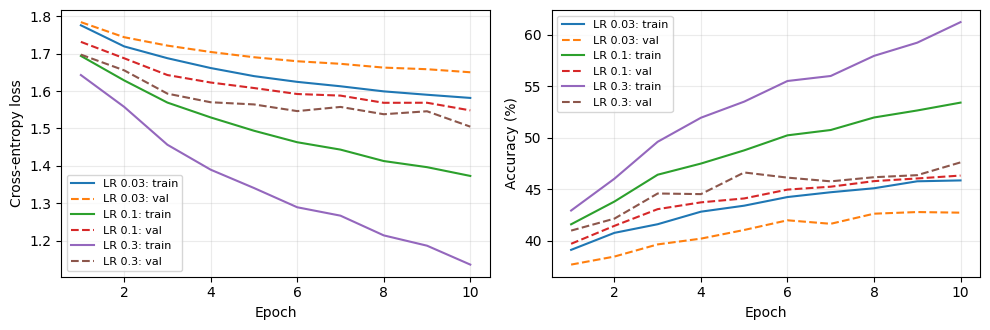

Selected initial learning rate: 0.3


In [31]:
from torch.utils.data import random_split

Q1_VAL_SIZE = 5000

q1_tuning_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=cifar_transform,
)

q1_train_subset, q1_val_subset = random_split(
    q1_tuning_dataset,
    [
        len(q1_tuning_dataset) - Q1_VAL_SIZE,
        Q1_VAL_SIZE,
    ],
    generator=torch.Generator().manual_seed(SEED),
)


def q1_validation_loaders():
    return {
        "train": make_loader(
            q1_train_subset, Q1_BATCH_SIZE, shuffle=True
        ),
        "train_eval": make_loader(
            q1_train_subset, Q1_BATCH_SIZE, shuffle=False
        ),
        "val": make_loader(
            q1_val_subset, Q1_BATCH_SIZE, shuffle=False
        ),
    }


q1_tuning_histories = {}
q1_tuning_rows = []

for candidate_lr in Q1_LR_CANDIDATES:
    print(f"\nInitial learning rate: {candidate_lr}")

    seed_everything()
    tuning_loaders = q1_validation_loaders()
    tuning_params = q1_init()

    tuning_history = q1_train(
        tuning_params,
        tuning_loaders,
        initial_lr=candidate_lr,
        heldout="val",
    )

    name = f"LR {candidate_lr}"
    q1_tuning_histories[name] = tuning_history
    final = tuning_history[-1]

    q1_tuning_rows.append({
        "Initial learning rate": candidate_lr,
        "Training accuracy (%)": 100 * final["train_acc"],
        "Validation accuracy (%)": 100 * final["val_acc"],
        "Validation loss": final["val_loss"],
    })

q1_tuning_table = (
    pd.DataFrame(q1_tuning_rows)
    .sort_values(
        ["Validation accuracy (%)", "Validation loss"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

Q1_SELECTED_LR = float(
    q1_tuning_table.loc[0, "Initial learning rate"]
)

# Save results before displaying the plots.
RESULT_DIR.mkdir(parents=True, exist_ok=True)

q1_tuning_table.to_csv(
    RESULT_DIR / "q1_learning_rate_comparison.csv",
    index=False,
)

pd.concat(
    [
        pd.DataFrame(history).assign(candidate=name)
        for name, history in q1_tuning_histories.items()
    ],
    ignore_index=True,
).to_csv(
    RESULT_DIR / "q1_learning_rate_histories.csv",
    index=False,
)

display(q1_tuning_table.round(4))
plot_histories(q1_tuning_histories, heldout="val")

print(f"Selected initial learning rate: {Q1_SELECTED_LR}")

Final training on all 50,000 training images
Initial learning rate: 0.3
Epoch 01/10 | Train loss: 1.6737, accuracy: 40.84% | Test loss: 1.7091, accuracy: 39.15%
Epoch 02/10 | Train loss: 1.5272, accuracy: 47.04% | Test loss: 1.5979, accuracy: 44.67%
Epoch 03/10 | Train loss: 1.4751, accuracy: 47.93% | Test loss: 1.5897, accuracy: 44.30%
Epoch 04/10 | Train loss: 1.4012, accuracy: 51.45% | Test loss: 1.5488, accuracy: 46.46%
Epoch 05/10 | Train loss: 1.3537, accuracy: 53.02% | Test loss: 1.5285, accuracy: 47.53%
Epoch 06/10 | Train loss: 1.2866, accuracy: 55.26% | Test loss: 1.5055, accuracy: 48.02%
Epoch 07/10 | Train loss: 1.2414, accuracy: 56.91% | Test loss: 1.5040, accuracy: 48.09%
Epoch 08/10 | Train loss: 1.1992, accuracy: 58.56% | Test loss: 1.4910, accuracy: 49.32%
Epoch 09/10 | Train loss: 1.1715, accuracy: 59.37% | Test loss: 1.4819, accuracy: 49.42%
Epoch 10/10 | Train loss: 1.1376, accuracy: 60.60% | Test loss: 1.4806, accuracy: 49.24%


Model / method,Training loss,Training accuracy (%),Test loss,Test accuracy (%)
Manual dense network,1.1376,60.60,1.4806,49.24


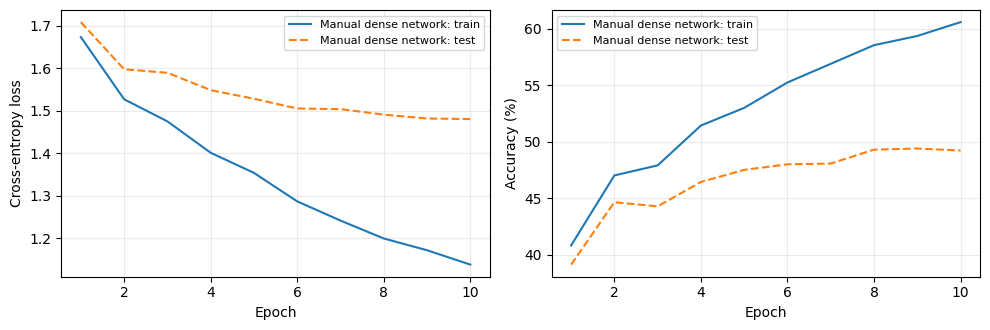

Training and evaluation time: 5.16 minutes


In [32]:
seed_everything()

q1_loaders = cifar_loaders()
q1_params = q1_init()

print(
    "Final training on all 50,000 training images\n"f"Initial learning rate: {Q1_SELECTED_LR}")

q1_start_time = time.perf_counter()

q1_history = q1_train(
    q1_params,
    q1_loaders,
    initial_lr=Q1_SELECTED_LR,
    heldout="test",
)

q1_elapsed = time.perf_counter() - q1_start_time

q1_results = {
    "Manual dense network": {
        key: q1_history[-1][key]
        for key in (
            "train_loss",
            "train_acc",
            "test_loss",
            "test_acc",
        )
    }
}

save_run(
    "q1_manual_tuned",
    q1_history,
    {
        **q1_results["Manual dense network"],
        "epochs": Q1_EPOCHS,
        "batch_size": Q1_BATCH_SIZE,
        "initial_lr": Q1_SELECTED_LR,
        "lr_decay": Q1_LR_DECAY,
        "selection_method": "Final-epoch validation accuracy",
        "validation_size": Q1_VAL_SIZE,
        "lr_candidates": Q1_LR_CANDIDATES,
        "elapsed_seconds": q1_elapsed,
    },
    q1_params,
)

result_table(["Manual dense network"], q1_results)
plot_histories({"Manual dense network": q1_history})

print(
    f"Training and evaluation time: "
    f"{q1_elapsed / 60:.2f} minutes"
)

### Results and discussion

After 10 epochs, the final network achieved a training accuracy of **60.60%** and a test accuracy of **49.24
%**, with cross-entropy losses of **1.1376** and **1.480**, respectively.

During learning-rate selection, increasing the initial learning rate improved both training and validation performance. However, the selected setting produced a training–validation accuracy gap of approximately 13.61 percentage points, suggesting overfitting.

The model has only one hidden layer and does not explicitly exploit local image structure through convolution. These architectural limitations may restrict its classification performance.